## Introdução

Como analista de dados, seu objetivo é avaliar como a mobilidade urbana se relaciona com a produtividade econômica nas principais cidades latino-americanas.

Para isso, você trabalhará com dados reais do TomTom Traffic Index e da OECD Cities, que deverão ser limpos, combinados e analisados para identificar em quais cidades vale a pena investir em infraestrutura de transporte.

## 🧩 Etapa 1: Carregar e explorar

Antes de limpar ou combinar os dados, é necessário **se familiarizar com a estrutura dos dois datasets**.

Nesta etapa, você validará se os arquivos foram carregados corretamente, conhecerá suas colunas e tipos de dados, e identificará possíveis inconsistências.

### 1.1 Carregamento dos dados e visualização rápida

**🎯 Objetivo:**
Importar as bibliotecas necessárias, carregar os arquivos CSV em DataFrames e realizar uma revisão preliminar para entender seu conteúdo.

**Instruções:**
- Importe as bibliotecas `pandas`, `numpy`, `seaborn` e `matplotlib.pyplot`.
- Carregue os arquivos usando `pd.read_csv()`:
  - `'/datasets/tomtom_traffic.csv'`
  - `'/datasets/oecd_city_economy.csv'`
- Salve os DataFrames nas variáveis `traffic` e `eco`.
- Mostre as primeiras 5 linhas de cada DataFrame.



In [1]:
# Importar bibliotecas
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


In [2]:
#Carregar arquivos
traffic = pd.read_csv('/datasets/tomtom_traffic.csv')
eco = pd.read_csv('/datasets/oecd_city_economy.csv')



In [3]:
print(traffic.head(5))# Mostrar as primeiras 5 linhas de traffic

  Country       City            UpdateTimeUTC  JamsDelay  TrafficIndexLive  \
0     ARE  abu-dhabi  2025-01-13 04:01:30.001      650.7              36.0   
1     ARE  abu-dhabi  2025-01-13 03:46:00.000      540.4              30.0   
2     ARE  abu-dhabi  2025-01-13 02:46:30.000       71.8               7.0   
3     ARE  abu-dhabi  2025-01-13 01:46:30.001        8.2               2.0   
4     ARE  abu-dhabi  2025-01-13 00:01:30.000        1.1               1.0   

   JamsLengthInKms  JamsCount  TrafficIndexWeekAgo     UpdateTimeUTCWeekAgo  \
0            109.1      162.0                 30.0  2025-01-06 04:01:30.000   
1            101.4      136.0                 27.0  2025-01-06 03:46:30.001   
2             18.9       23.0                  6.0  2025-01-06 02:46:30.000   
3              4.1        2.0                  2.0  2025-01-06 01:46:30.000   
4              0.2        1.0                  1.0  2025-01-06 00:01:30.000   

   TravelTimeLivePer10KmsMins  TravelTimeHistoricPer10Km

In [4]:
print(eco.head(5))# Mostrar as primeiras 5 linhas de eco

   Year            City    Country City GDP/capita Unemployment %  \
0  2023    buenos-aires  Argentina       15.782,00           6.2%   
1  2023       sao-paulo     Brazil       14.475,00           9.1%   
2  2023  rio-de-janeiro     Brazil       13.142,00           9.8%   
3  2023        brasilia     Brazil       15.999,00           8.3%   
4  2023        salvador     Brazil        8.761,00          13.1%   

  PM2.5 (μg/m³) Population (M)  
0          15,2          15,30  
1         29,50          22,50  
2         19,10          13,60  
3         13,50           4,70  
4         16,00           3,90  


**Dica**: se você não usar `print()`, a tabela ficará melhor.


---

## 🧩 Etapa 2: Explorar, limpar e preparar os dados

Antes de combinar os datasets, inspecione sua estrutura, tipos de dados, colunas e valores ausentes.

Anote as colunas que precisam de limpeza e, depois, padronize os nomes das colunas.

### 2.1 Explorar a estrutura e os tipos de dados

**🎯 Objetivo:**
Identificar colunas com tipos incorretos, distribuição e valores nulos, além de anotar as colunas que exigem conversão.

**Instruções:**

- Use `.info()` para conhecer a estrutura dos dois DataFrames.
- Mostre as primeiras 3 linhas de cada DataFrame.
- Identifique se os detalhes de cada DataFrame estão corretos ou se exigem ajustes, e escreva suas conclusões no bloco Markdown.
  - Há colunas que exigem conversão? Quais são? Que tipo de dado elas têm e qual deveriam ter?
  - Há dados ausentes em alguma coluna?


In [5]:
traffic.info()# Examinar a estrutura de traffic


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1004464 entries, 0 to 1004463
Data columns (total 12 columns):
 #   Column                          Non-Null Count    Dtype  
---  ------                          --------------    -----  
 0   Country                         1004464 non-null  object 
 1   City                            1004464 non-null  object 
 2   UpdateTimeUTC                   1004464 non-null  object 
 3   JamsDelay                       1004464 non-null  float64
 4   TrafficIndexLive                1004464 non-null  float64
 5   JamsLengthInKms                 1004464 non-null  float64
 6   JamsCount                       1004464 non-null  float64
 7   TrafficIndexWeekAgo             1004464 non-null  float64
 8   UpdateTimeUTCWeekAgo            1004464 non-null  object 
 9   TravelTimeLivePer10KmsMins      1004464 non-null  float64
 10  TravelTimeHistoricPer10KmsMins  1004464 non-null  float64
 11  MinsDelay                       1004464 non-null  float64
dtype

Na estrutura do DataFrame `traffic`, observa-se que:

- As colunas `UpdateTimeUTC` e `UpdateTimeUTC` são do tipo ...
- ...

In [6]:
eco.info()# Examinar a estrutura de eco


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Year             30 non-null     int64 
 1   City             30 non-null     object
 2   Country          30 non-null     object
 3   City GDP/capita  30 non-null     object
 4   Unemployment %   30 non-null     object
 5   PM2.5 (μg/m³)    30 non-null     object
 6   Population (M)   30 non-null     object
dtypes: int64(1), object(6)
memory usage: 1.8+ KB


Na estrutura do DataFrame `eco`, observa-se que:

- As colunas `City GDP/capita`, `Unemployment %`, ...
- ...

### 2.2 Renomear colunas

**🎯 Objetivo:**
Padronizar os nomes das colunas para evitar erros e facilitar a união dos datasets.

**Instruções:**

- Altere os nomes das colunas para que fiquem no formato `snake_case`.
    - `Country` → `country`
    - `UpdateTimeUTC` → `update_time_utc`
- Verifique se as alterações foram aplicadas corretamente usando `.columns`.


In [7]:
# Padronizar os nomes das colunas de traffic
# seu código aqui
traffic = traffic.rename(columns = {'Country' : 'country', 'UpdateTimeUTC' : 'update_time_utc', 'UpdateTimeUTCWeekAgo' : 'update_time_utc_week_ago',
                                   'JamsLengthInKms':'jams_length_kms', 'JamsCount':'jams_count', 'TrafficIndexWeekAgo': 'traffic_index_week_ago',
                                   'TravelTimeLivePer10KmsMins': 'travel_time_live_per_10kms_mins', 
                                   'TravelTimeHistoricPer10KmsMins':'travel_time_hist_per_10kms_mins','MinsDelay': 'mins_delay',
                                   'City':'city', 'TrafficIndexLive':'traffic_index_live', 'JamsDelay': 'jams_delay'})
# verificar alterações
traffic.columns

Index(['country', 'city', 'update_time_utc', 'jams_delay',
       'traffic_index_live', 'jams_length_kms', 'jams_count',
       'traffic_index_week_ago', 'update_time_utc_week_ago',
       'travel_time_live_per_10kms_mins', 'travel_time_hist_per_10kms_mins',
       'mins_delay'],
      dtype='object')

In [8]:
# Padronizar os nomes das colunas de eco
# seu código aqui

eco = eco.rename( columns = {"Country" : "country","City GDP/capita" : "city_gdp_capita", "Unemployment %":"unemployment_pct" , 
                             "Population (M)": "population_m", "Year": "year", 
                             "PM2.5 (μg/m³)": "pm25", "City":"city" })
# verificar alterações
eco.columns


Index(['year', 'city', 'country', 'city_gdp_capita', 'unemployment_pct',
       'pm25', 'population_m'],
      dtype='object')

### 2.3 Corrigir formatos numéricos e de data

**🎯 Objetivo:**
Garantir que as colunas de datas e valores numéricos estejam nos formatos corretos para permitir análises, cálculos e comparações precisas.

**Instruções:**

- Converta as colunas de data de `traffic` para o formato `datetime`. Faça a alteração de forma resistente a erros.
- No dataset `eco`, limpe os valores numéricos:
    - Em `city_gdp_capita`: remova separadores de milhares (`.`) e substitua as vírgulas (`','`) por pontos (`'.'`) antes de converter para o tipo `float`.
    - Em `unemployment_pct`: remova o símbolo de porcentagem (`%`) e substitua as vírgulas (`','`) por pontos (`'.'`) antes de converter para o tipo `float`.
    - Em `population_m`: substitua as vírgulas (`','`) por pontos (`'.'`) antes de converter para o tipo `float`.
- Por fim, crie uma nova coluna chamada `population`, multiplicando `population_m` por 1.000.000 para obter a população total.




<details>
<summary>Clique para ver a dica</summary>
Para remover símbolos, você pode substituí-los por um texto vazio.

In [9]:
# Converter as colunas de traffic para o tipo data com pd.to_datetime()
traffic['update_time_utc'] = pd.to_datetime(traffic['update_time_utc'], errors = "coerce") 
traffic['update_time_utc_week_ago'] = pd.to_datetime(traffic['update_time_utc_week_ago'], errors='coerce')#seu código aqui

# verificar a alteração
traffic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1004464 entries, 0 to 1004463
Data columns (total 12 columns):
 #   Column                           Non-Null Count    Dtype         
---  ------                           --------------    -----         
 0   country                          1004464 non-null  object        
 1   city                             1004464 non-null  object        
 2   update_time_utc                  1004464 non-null  datetime64[ns]
 3   jams_delay                       1004464 non-null  float64       
 4   traffic_index_live               1004464 non-null  float64       
 5   jams_length_kms                  1004464 non-null  float64       
 6   jams_count                       1004464 non-null  float64       
 7   traffic_index_week_ago           1004464 non-null  float64       
 8   update_time_utc_week_ago         1004464 non-null  datetime64[ns]
 9   travel_time_live_per_10kms_mins  1004464 non-null  float64       
 10  travel_time_hist_per_10kms_min

In [10]:

# Limpar separadores e converter colunas numéricas em eco
# eco['city_gdp_capita'] = ....astype(str).str.replace('.', '').str.replace(',', '.').astype(float)
# eco['unemployment_pct'] = ...
# eco['population_m'] = ...
eco['city_gdp_capita'] = eco['city_gdp_capita'].astype('string')\
.str.replace('.','', regex = False).str.replace(',','.',regex = False)\
.astype(float)

eco['unemployment_pct'] = eco['unemployment_pct'].astype('string')\
.str.replace('%','', regex = False).str.replace(',','.',regex = False)\
.astype(float)

eco['population_m'] = eco['population_m'].astype('string')\
.str.replace(',','.',regex = False)\
.astype(float)

eco['pm25'] = eco['pm25'].astype(str).str.replace(',', '.', regex=False).astype(float)

# Calcular a população total em unidades absolutas (multiplicar por 1000000)
# eco['population'] = ...
eco['population'] = eco['population_m'] * 1000000

# verificar a alteração
eco.info()
eco.head(3)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   year              30 non-null     int64  
 1   city              30 non-null     object 
 2   country           30 non-null     object 
 3   city_gdp_capita   30 non-null     float64
 4   unemployment_pct  30 non-null     float64
 5   pm25              30 non-null     float64
 6   population_m      30 non-null     float64
 7   population        30 non-null     float64
dtypes: float64(5), int64(1), object(2)
memory usage: 2.0+ KB


,year,city,country,city_gdp_capita,unemployment_pct,pm25,population_m,population
0,2023,buenos-aires,Argentina,15782.0,6.2,15.2,15.3,15300000.0
1,2023,sao-paulo,Brazil,14475.0,9.1,29.5,22.5,22500000.0
2,2023,rio-de-janeiro,Brazil,13142.0,9.8,19.1,13.6,13600000.0



---

## 🧩 Etapa 3: Extrair ano e filtrar

Extrair o ano permite filtrar as informações e trabalhar apenas com o período mais recente e relevante.

### 3.1 Extrair a coluna de ano e filtrar 2024

**🎯 Objetivo:**
Identificar o ano de cada registro e manter apenas os registros de 2024.

**Instruções:**

- Como o DataFrame `traffic` não tem uma coluna de ano, use o atributo `.dt.year` sobre sua coluna de data para criar uma nova coluna chamada `year`.
- Filtre as linhas em que o ano seja **2024**.
- Use `.copy()` para criar dois novos DataFrames (`traffic_2024` e `eco_2024`) e evitar modificar o dataset original.


In [11]:
# Extrair o ano das datas em update_time_utc
# traffic['year'] = ...
traffic['year'] = traffic['update_time_utc'].dt.year
# Verificar alteração
traffic.head(3)

,country,city,update_time_utc,jams_delay,traffic_index_live,jams_length_kms,jams_count,traffic_index_week_ago,update_time_utc_week_ago,travel_time_live_per_10kms_mins,travel_time_hist_per_10kms_mins,mins_delay,year
0,ARE,abu-dhabi,2025-01-13 04:01:30.001,650.7,36.0,109.1,162.0,30.0,2025-01-06 04:01:30.000,11.614767,10.265330,1.349437,2025
1,ARE,abu-dhabi,2025-01-13 03:46:00.000,540.4,30.0,101.4,136.0,27.0,2025-01-06 03:46:30.001,11.003180,10.031544,0.971635,2025
2,ARE,abu-dhabi,2025-01-13 02:46:30.000,71.8,7.0,18.9,23.0,6.0,2025-01-06 02:46:30.000,8.196278,8.196510,-0.000232,2025


In [12]:

# Filtrar os registros do ano de 2024
# traffic_2024 = traffic[...].copy()
# eco_2024 = ...
traffic_2024 = traffic[traffic['year'] == 2024].copy()
eco_2024 = eco[eco['year'] == 2024].copy()
# Revisar os novos DataFrames
display(traffic_2024.head())
display(eco_2024.head())



,country,city,update_time_utc,jams_delay,traffic_index_live,jams_length_kms,jams_count,traffic_index_week_ago,update_time_utc_week_ago,travel_time_live_per_10kms_mins,travel_time_hist_per_10kms_mins,mins_delay,year
302,ARE,abu-dhabi,2024-12-31 23:01:30.000,12.9,5.0,2.5,5.0,2.0,2024-12-24 23:01:30.001,8.560399,8.519634,0.040765,2024
303,ARE,abu-dhabi,2024-12-31 22:01:30.000,136.0,21.0,20.6,32.0,3.0,2024-12-24 22:01:30.000,10.355732,9.049445,1.306286,2024
304,ARE,abu-dhabi,2024-12-31 21:16:30.000,455.2,31.0,40.4,72.0,4.0,2024-12-24 21:01:30.000,11.456878,9.305174,2.151704,2024
305,ARE,abu-dhabi,2024-12-31 20:01:00.001,399.4,27.0,38.0,75.0,6.0,2024-12-24 20:01:30.001,11.670062,9.952811,1.717252,2024
306,ARE,abu-dhabi,2024-12-31 19:46:00.000,366.4,28.0,39.8,82.0,9.0,2024-12-24 19:01:00.000,11.686322,10.008469,1.677853,2024


,year,city,country,city_gdp_capita,unemployment_pct,pm25,population_m,population
15,2024,buenos-aires,Argentina,18117.0,7.2,14.5,15.4,15400000.0
16,2024,sao-paulo,Brazil,14703.0,8.5,28.0,22.6,22600000.0
17,2024,rio-de-janeiro,Brazil,13349.0,9.2,18.4,13.7,13700000.0
18,2024,brasilia,Brazil,16251.0,7.8,12.8,4.8,4800000.0
19,2024,salvador,Brazil,8899.0,12.4,15.2,3.9,3900000.0



---

## 🧩 Etapa 4: Analisar e resumir dados de mobilidade

Como o dataset de tráfego contém **múltiplos registros por cidade**, nesta parte você calculará as médias anuais por cidade para simplificar a análise e obter uma visão mais clara das tendências gerais.

### 4.1 Calcular médias de tráfego por cidade

**🎯 Objetivo:**
Obter uma visão consolidada do tráfego médio por cidade e ano, para analisar padrões gerais sem depender de dados diários.

**Instruções:**

- Agrupe os dados por `city`, `country` e `year`.
- Calcule a média **apenas das métricas de tráfego mais relevantes**, como `jams_delay`, `traffic_index_live`, `jams_length_kms`, `jams_count`, `mins_delay` e tempos de viagem (`travel_time_live_per_10kms_mins` e `travel_time_hist_per_10kms_mins`).
- Salve o resultado como `traffic_city_year_2024` e mantenha as colunas como variáveis (não como índices).



<details>
<summary>Clique para ver a dica</summary>
Use `.agg()` para aplicar funções de média. Ao final, reinicie o índice para manter as colunas do agrupamento como variáveis (não como índices).


In [13]:
# Calcular as médias de tráfego por cidade, país e ano
traffic_city_year_2024 = (
    traffic_2024
    .groupby(['city', 'country', 'year'])[[
        'jams_delay', 'traffic_index_live', 'jams_length_kms', 'jams_count',
        'mins_delay', 'travel_time_live_per_10kms_mins', 'travel_time_hist_per_10kms_mins'
    ]]
    .agg('mean')
    .reset_index()
)


# Mostrar resultado
traffic_city_year_2024.head()

,city,country,year,jams_delay,traffic_index_live,jams_length_kms,jams_count,mins_delay,travel_time_live_per_10kms_mins,travel_time_hist_per_10kms_mins
0,a-coruna,ESP,2024,17.935187,15.259774,2.198002,4.934405,0.774172,16.267977,15.493804
1,aachen,DEU,2024,26.732141,20.960314,3.892586,6.601832,0.792968,13.397861,12.604894
2,aarhus,DNK,2024,21.200616,16.575891,2.736736,6.109987,0.495276,15.219292,14.724016
3,abu-dhabi,ARE,2024,171.157315,13.902028,24.507380,47.268019,0.139764,9.829092,9.689328
4,adana,TUR,2024,83.864761,22.541040,11.827331,23.754620,1.129749,15.879694,14.749945


### 🧠 **Momento de reflexão**

Excelente trabalho até aqui!

Agora que você já tem as médias anuais por cidade, é hora de **observá-las** com atenção.

Pense:

- Qual cidade você acha que tem o maior tempo médio de tráfego?
- Será uma cidade da **Europa**, da **América Latina** ou de **outra região** do mundo?

Para descobrir, execute esta linha de código:

`traffic_city_year_2024.sort_values(["jams_delay"], ascending=False)`

🔍 Observe qual cidade aparece nas primeiras posições.

Os resultados surpreendem você? Eles coincidem com o que você imaginava?


In [14]:
traffic_city_year_2024.sort_values(["jams_delay"], ascending=False)

,city,country,year,jams_delay,traffic_index_live,jams_length_kms,jams_count,mins_delay,travel_time_live_per_10kms_mins,travel_time_hist_per_10kms_mins
221,mexico-city,MEX,2024,2833.057892,34.218190,389.239265,594.969392,1.855542,21.809092,19.953550
352,tokyo,JPN,2024,2152.574357,36.805059,373.069734,518.809420,0.698152,22.443778,21.745626
246,new-york,USA,2024,2133.400000,28.210388,398.227892,544.474902,1.396351,18.505043,17.108691
200,london,GBR,2024,2050.703662,29.230166,287.632868,471.795554,1.325160,17.714139,16.388979
211,manila,PHL,2024,1741.493381,66.129402,246.858082,341.881205,2.469894,27.134629,24.664734
...,...,...,...,...,...,...,...,...,...,...
111,dunedin,NZL,2024,4.651175,15.430809,0.712315,1.591384,0.633294,16.226009,15.592715
363,uppsala,SWE,2024,4.194486,13.939168,0.656368,1.349672,0.501802,15.746717,15.244916
123,fujairah,ARE,2024,4.025959,10.907719,0.731910,1.373006,0.194951,11.662590,11.467639
12,almere,NLD,2024,3.633523,6.290478,0.506362,1.064063,-0.017544,9.467150,9.484694


A cidade com o maior tempo médio de tráfego é ...


---

## 🧩 Etapa 5: Unir mobilidade e economia

Combinar datasets permite analisar como os indicadores econômicos se relacionam com os de mobilidade.

### 5.1 Unir tráfego (tabela principal) com indicadores econômicos

**🎯 Objetivo:**
Combinar as informações de tráfego e economia em um único DataFrame para analisar como as condições econômicas se relacionam com a mobilidade urbana.

**Instruções:**

- Selecione apenas as **colunas relevantes** de cada dataset (por exemplo, variáveis-chave de tráfego e de economia).
- Use `.copy()` ao criar subconjuntos para evitar modificar o dataset original.
- Una os dois DataFrames e defina `city` e `year` como **chaves de união**.
- Mantenha apenas as cidades e anos presentes nos dois datasets.
- Salve o resultado em uma nova variável chamada `merged` e mostre as primeiras 5 li


<details>
<summary>Clique para ver a dica</summary>

Aplique uma união do tipo `inner` para manter as cidades e anos presentes nos dois datasets.

In [15]:


# Selecionar colunas-chave de tráfego e economia
left_cols = ['city','country','year','jams_delay','traffic_index_live',
             'jams_length_kms','jams_count','mins_delay',
             'travel_time_live_per_10kms_mins','travel_time_hist_per_10kms_mins']

right_cols = ['city','year','city_gdp_capita','unemployment_pct','pm25','population']

# Usar .copy() para criar os dois novos datasets reduzidos
# traffic_2024_small = traffic_city_year_2024[ ... ].copy()
# eco_2024_small = ...
traffic_2024_small = traffic_city_year_2024[left_cols].copy()
eco_2024_small = eco_2024[right_cols].copy()

# Unir datasets
merged = pd.merge(traffic_2024_small, eco_2024_small, on = ['city', 'year'], how = 'inner')

merged.head(5)
# Mostrar as primeiras 5 linhas
# seu código aqui



,city,country,year,jams_delay,traffic_index_live,jams_length_kms,jams_count,mins_delay,travel_time_live_per_10kms_mins,travel_time_hist_per_10kms_mins,city_gdp_capita,unemployment_pct,pm25,population
0,belo-horizonte,BRA,2024,263.047879,19.428946,44.038129,68.805422,0.487228,18.304538,17.817311,11124.0,9.5,16.8,6100000.0
1,bogota,COL,2024,1141.552364,37.614273,140.893564,230.566550,1.699628,24.992185,23.292557,11442.0,10.0,17.6,11300000.0
2,brasilia,BRA,2024,101.576326,11.258220,18.337133,27.280140,0.193442,13.338658,13.145216,16251.0,7.8,12.8,4800000.0
3,buenos-aires,ARG,2024,571.089593,17.756012,100.287844,137.359860,0.416566,17.907916,17.491349,18117.0,7.2,14.5,15400000.0
4,curitiba,BRA,2024,183.469274,14.954545,30.050044,46.898164,0.139965,17.258700,17.118736,12381.0,8.2,13.5,3700000.0



---

## 🧩 Etapa 6: Visualização e análise de relações

Agora que você tem um dataset limpo e unificado, é hora de **visualizar padrões**.

Os gráficos ajudarão você a entender como as variáveis econômicas se relacionam com as de mobilidade urbana.

### 6.1 Visualizar relações entre economia e tráfego

**🎯 Objetivo:**
Analisar visualmente a distribuição e a relação entre indicadores de tráfego e economia em 2024, para identificar possíveis padrões ou tendências gerais entre essas variáveis.

**Instruções:**

- Use as bibliotecas `seaborn` e `matplotlib.pyplot` para gerar os gráficos.
- Visualize a distribuição do **tráfego** (`jams_delay`) usando:
    - **Boxplot** → para observar a média, a mediana e detectar valores atípicos.
- Visualize a distribuição da **economia** (`city_gdp_capita`) usando:
    - **Histograma** → para analisar o formato da distribuição e o valor médio do PIB per capita.
- Por fim, **compare as duas variáveis** para observar se existe alguma relação entre elas, criando um único gráfico de barras em que apareçam os dois indicadores.
- Lembre-se de adicionar título e rótulos aos eixos dos seus gráficos.
- Observe e comente os padrões, valores extremos ou possíveis relações que você identificar.


**Dica:** Dentro dos parênteses do boxplot, adicione `showmeans=True` para ver a média no gráfico.


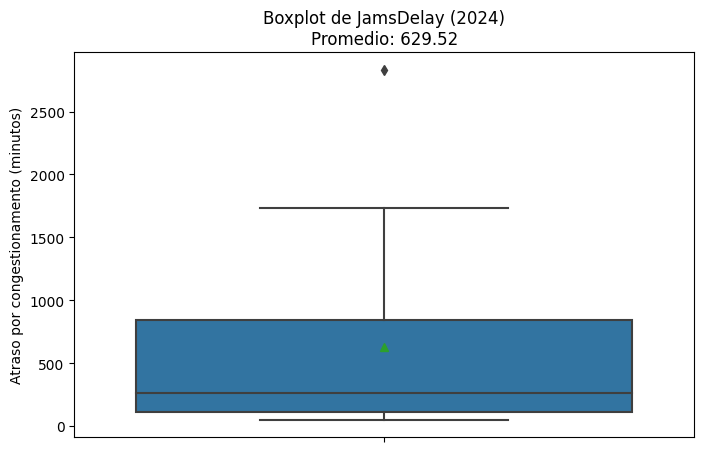

In [16]:
# Criar boxplot para observar o comportamento dos minutos de congestionamento JamsDelay
# crie seu gráfico
plt.figure(figsize=(8, 5))
sns.boxplot(y=merged['jams_delay'], showmeans=True)
plt.ylabel('Atraso por congestionamento (minutos)')

# obter média para mostrá-la no título
mean_value = merged['jams_delay'].mean()
plt.title(f'Boxplot de JamsDelay (2024)\nPromedio: {mean_value:.2f}')
plt.show()


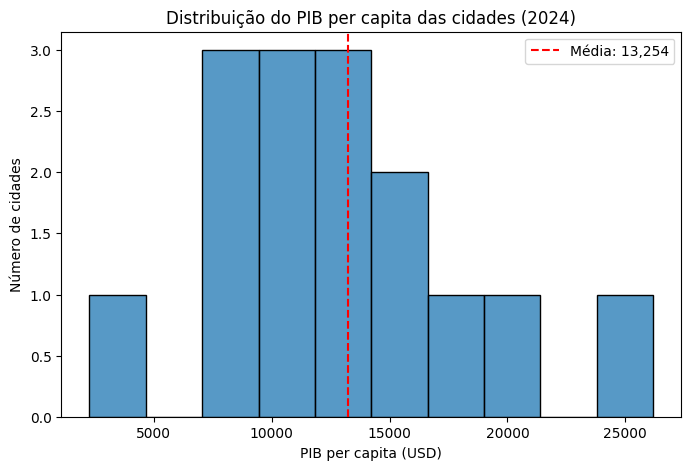

In [17]:
# Criar histograma para ver a distribuição da economia (city_gdp_capita)
plt.figure(figsize=(8, 5))
sns.histplot(data=merged, x='city_gdp_capita', bins=10)
# linha vertical com a média
mean_gdp = merged['city_gdp_capita'].mean()
plt.axvline(mean_gdp, color='red', linestyle='--', label=f'Média: {mean_gdp:,.0f}')

plt.title('Distribuição do PIB per capita das cidades (2024)')
plt.xlabel('PIB per capita (USD)')
plt.ylabel('Número de cidades')
plt.legend()
plt.show()


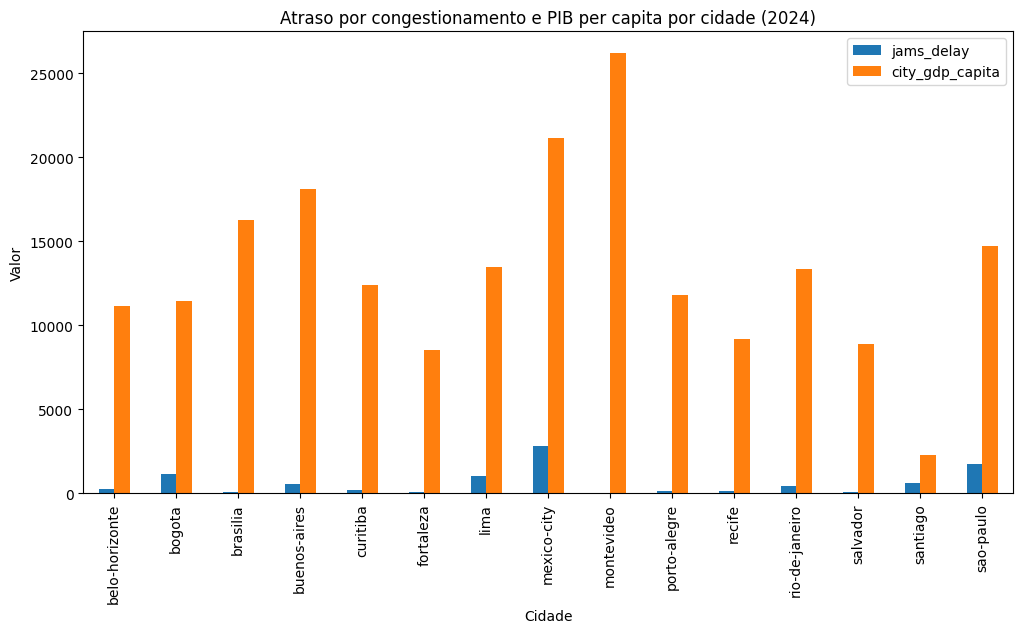

In [18]:
# Gráfico de barras para comparar jams_delay e city_gdp_capita por cidade
#merged.plot( ... , y=['jams_delay', 'city_gdp_capita'])

merged.plot(kind='bar', x='city', y=['jams_delay', 'city_gdp_capita'], figsize=(12, 6))

plt.title('Atraso por congestionamento e PIB per capita por cidade (2024)')
plt.xlabel('Cidade')
plt.ylabel('Valor')
plt.xticks(rotation=90)
plt.show()


**Tip:** Antes del `plt.show()` agrega el código `plt.xticks(rotation=90)` para rotar las etiquetas del eje X en 90 grados.

### 🧠 **Reflita**

Excelente trabalho chegando a esta etapa da análise. Antes de avançar, revise seus gráficos e reserve um momento para pensar:

- As cidades com maior PIB per capita também apresentam mais congestionamento?

- Ou acontece o contrário, ou não existe uma relação clara?

Escreva seus comentários:


---

## 🧩 Etapa 7: Exportar e documentar resultados

Nesta etapa final, você consolidará todo o seu trabalho: salvará o dataset limpo e criará um resumo que documente os resultados do projeto.

### 7.1 Salvar dataset final

**🎯 Objetivo:**
Gerar um CSV limpo, reproduzível e com colunas relevantes para análises posteriores.

**Instruções:**

- Exporte o DataFrame `merged` com o nome: `ladb_mobility_economy_2024_clean.csv`.
- Use `index=False` para não incluir o índice.e.


In [19]:
# Exporte o dataset final como CSV
merged.to_csv("ladb_mobility_economy_2024_clean.csv", index=False)

Para poder visualizar ou baixar o arquivo gerado:  
No menu lateral à esquerda, vá até a parte inferior, na seção de **Exportar dataset**, para mais informações.




---

## ✅ Entregáveis

1. **Notebook `.ipynb`** com todas as células (código + comentários).
2. **CSV final**: `ladb_mobility_economy_2024_clean.csv`.
3. **Resumo executivo breve** em Markdown (3–5 parágrafos).



---

# 🧾 Resumo executivo (modelo)

> Complete este resumo ao finalizar a análise. Mantenha 3–5 parágrafos curtos, claros e acionáveis.

**Contexto e objetivo:**  
- Responda à pergunta central da análise: que relação existe entre a mobilidade urbana (congestionamento, tempos de viagem) e a produtividade econômica (PIB per capita)?
- Explique brevemente as variáveis-chave utilizadas e sua relevância para a tomada de decisões.

**Cobertura dos dados:**  
- Especifique os anos analisados, o número de cidades e países incluídos.

**Metodologia (alto nível):**  
- Descreva os principais processos: limpeza de dados (formatos, padronização de colunas).
- Explique a agregação por cidade–ano e o uso de uma união `INNER` para integrar tráfego e economia.
- Mencione as validações visuais utilizadas (distribuições, outliers, tendências gerais).

**Achados iniciais:**  
- Resuma os padrões mais importantes entre índices de tráfego e PIB per capita.
- Destaque anomalias ou outliers que poderiam exigir revisão adicional ou uma análise mais profunda.

**Recomendações:**  
Conecte os achados a ações: cidades prioritárias, necessidade de validar fontes, necessidade de análises adicionais ou propostas de investimento.

- Qual cidade — Bogotá, Lima, Buenos Aires ou alguma outra em particular — apresenta a maior correlação significativa entre altos níveis de congestionamento veicular e baixos indicadores de produtividade econômica, sugerindo ser uma cidade prioritária para investimento em infraestrutura de transporte?


In [20]:
merged[['jams_delay', 'city_gdp_capita']].corr()

,jams_delay,city_gdp_capita
jams_delay,1.000000,0.282975
city_gdp_capita,0.282975,1.000000


## Resumo executivo

**Contexto e objetivo**

Esta análise investiga que relação existe entre a mobilidade urbana e a produtividade econômica em cidades da América Latina, com o objetivo de apoiar a decisão sobre onde investir em infraestrutura de transporte. O indicador de tráfego principal é o `jams_delay` (atraso total causado por congestionamentos, em minutos), complementado por `traffic_index_live`, `mins_delay` e pelos tempos de viagem a cada 10 km. A produtividade é medida pelo `city_gdp_capita` (PIB per capita em USD), com apoio de desemprego, poluição (`pm25`) e população.

**Cobertura dos dados**

Foram analisados dados de 2024 de 15 cidades latino-americanas em 7 países: Brasil (9 cidades), Argentina, Chile, Colômbia, México, Peru e Uruguai. A base de tráfego (TomTom) tinha mais de 1 milhão de registros de 387 cidades do mundo, e o INNER JOIN com a base econômica (OECD) manteve as 15 cidades presentes nas duas fontes, sem perdas.

**Metodologia**

Os nomes das colunas foram padronizados em `.rename()` e os tipos corrigidos: datas convertidas com `pd.to_datetime` e valores numéricos do dataset econômico limpos (separadores de milhares, vírgulas decimais e símbolo de %). Depois de extrair o ano e filtrar 2024, os dados de tráfego foram agregados pela média por cidade, país e ano e unidos ao dataset econômico por um INNER JOIN em `city` e `year`. A validação foi visual, com boxplot (distribuição do atraso e outliers), histograma (distribuição do PIB per capita) e gráfico de barras comparando os dois indicadores por cidade.

**Achados iniciais**

Não se observa uma relação clara entre riqueza e congestionamento: a correlação entre `jams_delay` e `city_gdp_capita` foi de 0,28 (positiva e fraca) e, com apenas 15 cidades, deve ser vista como indício, não como conclusão. Montevidéu tem o maior PIB per capita (cerca de 26 mil USD) e quase nenhum atraso, enquanto Bogotá (cerca de 11,4 mil USD) e Lima têm atrasos elevados. O `jams_delay` tem distribuição assimétrica, com média de 629,5 min bem acima da mediana (cerca de 263 min). Mexico City é o outlier (cerca de 2.833 min) e também a cidade mais congestionada entre as 387 do dataset de tráfego, à frente de Tokyo, New York e London. Mexico City, São Paulo, Bogotá e Lima lideram o atraso entre as 15 cidades, mas Buenos Aires e Rio, mais populosas que Bogotá, têm atrasos menores, então o efeito do tamanho da cidade é uma hipótese a testar. Santiago apresenta PIB per capita de cerca de 2,3 mil USD, muito abaixo das demais, valor que precisa ser validado na fonte.

**Recomendações**

Bogotá é a candidata mais forte à prioridade, por combinar alto congestionamento (cerca de 1.141 min, 3º entre as 15 cidades) e PIB per capita (cerca de 11,4 mil USD) abaixo da mediana do grupo. Santiago também teria perfil prioritário (PIB muito baixo e atraso acima da mediana), mas só depois de validar seu dado. Lima e São Paulo têm congestionamento alto, porém PIB acima da mediana, e seriam prioridade pelo volume de tráfego, não pela baixa produtividade. Como há uma observação por cidade em um único ano, não é possível calcular uma correlação por cidade, então o critério usado foi a combinação de atraso alto e PIB baixo. Antes de investir, recomenda-se validar o dado de Santiago, incluir `population` na análise para separar o efeito do tamanho da cidade e repetir o estudo com mais anos.